# Part 1: simple, methodical experiments

**Result:** remove PCA/GMM from Ani's recipe and use three self-training passes: **0.913191 sample F1**, versus **0.908865** for the frozen training-only Ani reference and **0.888316** for DBSCAN. This is a small development-fold improvement, **not a demonstrated Kaggle improvement**. Later-year checks do not confirm it, so the historical reference remains in place. The roughly 0.05 gain we wanted has **not** been achieved.

The selected implementation is [simple_solution.py](simple_solution.py). The separate [candidate CSV](experiments/simple_methodical/candidate/part1_simple_submission.csv) contains 312 checked predictions and has not been uploaded. It has no Kaggle score.

## Reasoning from the PDF and features

`Midterm_Project.pdf`, pages 4–5, says the 150 embeddings encode the actual stopping-reason text, are PCA-reduced and randomly rotated, and have small magnitudes. They directly describe the target. Eligibility criteria, diseases and drug biology describe the trial indirectly; matched drug features are absent for about 44% of training/validation rows. Start year identifies distribution shift but is not the meaning of a stopping reason. We first test simple models of the reason embeddings. IDs are identifiers only. No online data, external labels, reverse engineering of test labels, or deep learning is used.

There are 235 known trials: 216 have one reason and 19 have two. Label counts: Safety 25, Funding 12, Efficacy 31, Recruitment 151, Other 35. Global exploratory inspection found 82 labeled trials with a near-identical labeled embedding neighbor, all with agreeing labels. That motivated local methods; those inspection statistics are not fitted predictors.

## Unchanged benchmark

We reuse the exact eight saved repeats of five folds: 188 verified fitting rows, 47 held-out rows, and 1,014 originally unlabeled training rows. Every learned scaler, PCA, clusterer, graph and classifier excludes held-out and Kaggle test inputs. Pool all 235 out-of-fold predictions within each repeat, calculate sample F1, then average eight repeat scores. Also retain macro/per-reason F1, repeat SD and paired comparisons.

These are repeatedly used **development folds**, including the former validation labels. They are not an untouched test estimate. There are 127 named evaluations, including repeated controls and nearby settings; all positive and negative results are retained. Repeated folds overlap and are not independent samples.

## Ordered experiments

1. Nearest neighbors, logistic regression, joint logistic regression, shrinkage LDA and RBF SVM. Compare coordinate standardization with a single scale preserving rotation, plus small normalization/PCA controls.
2. Unlabeled structure: label spreading, direct K-means labels, and one cautious pseudo-labeling pass. The first graph attempt was aborted before scoring because isolated unlabeled components produce undefined probabilities; the recorded replacement uses a nearest-verified-neighbor fallback.
3. Preserve observed label combinations, or use smooth RBF regression boundaries. Neither beats Ani.
4. Test pseudo-label weights and passes. Remove Ani's PCA/GMM while retaining its joint logistic model and cosine neighbors. This gives the first improvement.
5. Downweight repeated reason texts and try balanced binary class weights. Neither beats Ani.
6. Change one setting at a time around the simplified recipe. A third pass helps; most other changes hurt.
7. Check more passes and neighbor choices, then freeze the three-pass recipe before later-year diagnostics. Five/ten passes and alternative neighbors do not improve it.

The final model does not combine all these experiments. The best pure logistic model scores 0.899876; independent-logistic self-training reaches 0.904947. The simplest tested alternatives do not explain a 0.05 leaderboard gap.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
PART1 = Path.cwd()
if not (PART1 / 'data/part1_train.csv').exists():
    PART1 = PART1 / 'part1'
assert (PART1 / 'data/part1_train.csv').exists()
OUT = PART1 / 'experiments/simple_methodical'
results = pd.read_csv(OUT / 'all_results.csv')
names = ['ani_train_only','dbscan_train_only','logistic_scalar_C1_t0.3',
         'selftrain_C1_w1_r1','joint_standard_knn0.3_r2','final_control_r3']
comparison = results[results.name.isin(names)].drop_duplicates('name').set_index('name')
display(comparison[['mean_f1','repeat_sd','macro_f1','delta_ani','repeat_wins_ani',
                    'fold_wins_ani','fold_ties_ani']].sort_values('mean_f1', ascending=False))


,mean_f1,repeat_sd,macro_f1,delta_ani,repeat_wins_ani,fold_wins_ani,fold_ties_ani
name,,,,,,,
final_control_r3,0.913191,0.003598,0.825249,0.004326,6.0,20.0,11.0
joint_standard_knn0.3_r2,0.911613,0.004564,0.823920,0.002748,6.0,18.0,12.0
ani_train_only,0.908865,0.006631,0.822043,0.000000,0.0,0.0,40.0
selftrain_C1_w1_r1,0.904947,0.011063,0.829530,-0.003918,3.0,14.0,5.0
logistic_scalar_C1_t0.3,0.899876,0.007103,0.830211,-0.008989,0.0,11.0,4.0
dbscan_train_only,0.888316,0.003882,0.807876,-0.020550,0.0,7.0,2.0


## Selected recipe

Standardize the embeddings using the permitted training feature pool. Fit one multinomial logistic regression (`C=0.3`, `tol=1e-4`, maximum 3,000 iterations). A two-reason trial contributes half an example to each reason; inverse reason-frequency weights balance the expanded targets. Blend 70% logistic scores with 30% scores from ten cosine neighbors, weighted by squared positive similarity. Neighbor targets divide their mass across a trial's verified or generated reasons.

For each of three passes, accept originally unlabeled trials only when the highest blended score is at least 0.8. Rebuild the augmented set from verified labels plus currently accepted rows. Finally select scores at least 0.3, with an argmax fallback. These are class-proportion scores, not calibrated independent binary probabilities.

There is no PCA, GMM, DBSCAN, graph or auxiliary-feature model in the selected recipe. Full fitting uses 235 verified labels and accepts 691, 774 and 807 unlabeled rows across the three passes. It never fits on the 312 test rows.


In [2]:
display(comparison[[f'f1_{r}' for r in ['Safety','Funding','Efficacy','Recruitment','Other']]])
display(pd.read_csv(OUT / 'verification/paired_trial_bootstrap.csv'))


,f1_Safety,f1_Funding,f1_Efficacy,f1_Recruitment,f1_Other
name,,,,,
ani_train_only,0.907372,0.760623,0.869526,0.972481,0.600213
logistic_scalar_C1_t0.3,0.897049,0.824028,0.869907,0.964157,0.595916
dbscan_train_only,0.868164,0.753986,0.853972,0.956423,0.606836
joint_standard_knn0.3_r2,0.916882,0.760664,0.858914,0.976097,0.607044
selftrain_C1_w1_r1,0.917151,0.789902,0.880544,0.965428,0.594624
final_control_r3,0.925601,0.758076,0.859374,0.976895,0.606301


,name,reference,mean_delta,lower_95,upper_95,caveat
0,final_control_r3,ani_train_only,0.004326,-0.000709,0.009894,Trial bootstrap of development predictions; no...
1,final_control_r3,dbscan_train_only,0.024876,0.005425,0.046312,Trial bootstrap of development predictions; no...
2,joint_standard_knn0.3_r2,ani_train_only,0.002748,-0.001064,0.007004,Trial bootstrap of development predictions; no...
3,joint_standard_knn0.3_r2,dbscan_train_only,0.023298,0.004167,0.044131,Trial bootstrap of development predictions; no...


The selected model wins 20 of 40 folds, ties 11 and loses 9 against Ani; it wins six of eight repeat averages. Its +0.004326 difference has a descriptive trial-bootstrap interval of approximately **[-0.000709, +0.009894]**, including zero. Each trial's eight predictions stay together, but the interval does not adjust for model selection or correlated training fits. It does not establish a leaderboard improvement.

“Other” remains the main weakness (F1 about 0.606). Gains mostly come from Safety and Recruitment; Funding and Efficacy do not improve.

## Checks after freezing the candidate

The original 157/78 split has already influenced historical development; it is not new validation. Chronological windows train only on known and originally unlabeled trials starting at or before 2003, 2005 or 2007. Later known trials are held out; later unknown features are excluded too. These supplement, rather than replace, the fixed benchmark.


In [3]:
diagnostics = pd.read_csv(OUT / 'verification/diagnostic_scores.csv')
display(diagnostics[['split','name','verified_fit','unlabeled_fit','held','sample_f1','macro_f1']])
display(diagnostics.pivot(index='split', columns='name', values='sample_f1'))


,split,name,verified_fit,unlabeled_fit,held,sample_f1,macro_f1
0,original_validation,ani_train_only,157,1014,78,0.891026,0.710738
1,original_validation,final_control_r3,157,1014,78,0.884615,0.706258
2,original_validation,joint_standard_knn0.3_r2,157,1014,78,0.888889,0.710587
3,after_2003,ani_train_only,126,60,109,0.821101,0.776237
4,after_2003,final_control_r3,126,60,109,0.821101,0.776237
5,after_2003,joint_standard_knn0.3_r2,126,60,109,0.821101,0.776237
6,after_2005,ani_train_only,149,302,86,0.856589,0.807949
7,after_2005,final_control_r3,149,302,86,0.852713,0.798753
8,after_2005,joint_standard_knn0.3_r2,149,302,86,0.844961,0.793085
9,after_2007,ani_train_only,198,724,37,0.882883,0.856518


name,ani_train_only,final_control_r3,joint_standard_knn0.3_r2
split,,,
after_2003,0.821101,0.821101,0.821101
after_2005,0.856589,0.852713,0.844961
after_2007,0.882883,0.869369,0.896396
original_validation,0.891026,0.884615,0.888889


On the old 78-row validation set the three-pass candidate scores 0.884615 versus Ani's 0.891026. It ties Ani after 2003 and trails it after 2005 and 2007. The final window has only 37 known trials. These results support keeping the current reference; the CSV is an optional manual experiment, not a confirmed upgrade.

## Reproduction and files

The independent `simple_solution.py` implementation reproduces **all 40 selected-model fold probability arrays**, using `atol=1e-10, rtol=1e-8`. An independent refit of Ani using the original notebook recipe reproduces its first saved fold. Model reload gives exactly identical test scores. The candidate has 312 unique IDs in sample-submission order, with nonempty valid reasons.

`candidate/generated_labels.csv` distinguishes the 807 accepted fitting rows and their actual fitting targets from predictions for all 1,014 unlabeled trials. `candidate/part1_train_augmented.csv` preserves every original verified label. The PDF requires an unsupervised label-generation experiment: the evaluated K-means k=40 baseline has its own `candidate/kmeans_comparison_train_augmented.csv`; those labels are **not** the selected model's targets.

Each stage saves settings, input/fold checksums, scores and out-of-fold predictions. See [all results](experiments/simple_methodical/all_results.csv), the [candidate manifest](experiments/simple_methodical/candidate/manifest.json), and [checks](experiments/simple_methodical/verification/checks.json). Part 2 inputs, original data, old models, submissions and benchmark references were not replaced. Nothing was uploaded or committed/pushed.


In [4]:
manifest = json.loads((OUT / 'candidate/manifest.json').read_text())
display({k:manifest[k] for k in ['known_labels','final_self_training_counts','test_rows',
                               'independent_fold_replay_count','reload_exact','kaggle_score','versions']})
checks = pd.read_csv(OUT / 'candidate/independent_40_fold_replay.csv')
assert len(checks) == 40 and checks.max_abs_error.max() < 1e-8
display(checks.agg({'max_abs_error':['max']}))


{'known_labels': 235,
 'final_self_training_counts': [691, 774, 807],
 'test_rows': 312,
 'independent_fold_replay_count': 40,
 'reload_exact': True,
 'kaggle_score': None,
 'versions': {'python': '3.12.13',
  'sklearn': '1.9.0',
  'numpy': '2.5.2',
  'pandas': '3.0.5',
  'joblib': '1.6.0'}}

,max_abs_error
max,0.0


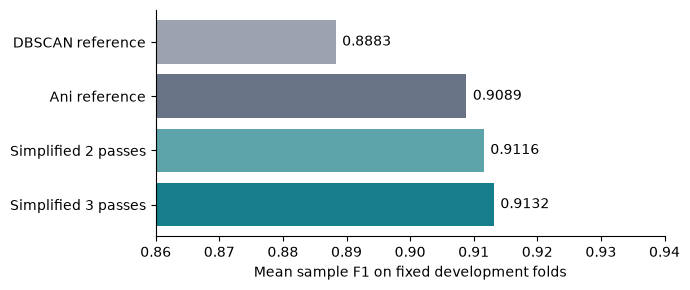

In [5]:
# Figure source and standalone export.
import matplotlib.pyplot as plt
labels = ['DBSCAN reference','Ani reference','Simplified 2 passes','Simplified 3 passes']
models = ['dbscan_train_only','ani_train_only','joint_standard_knn0.3_r2','final_control_r3']
values = comparison.loc[models, 'mean_f1'].to_numpy()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(labels[::-1], values[::-1], color=['#167d8d','#5ca4a9','#697386','#9ca3af'])
ax.set_xlim(.86, .94)
ax.set_xlabel('Mean sample F1 on fixed development folds')
for i, value in enumerate(values[::-1]):
    ax.text(value + .001, i, f'{value:.4f}', va='center')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / 'comparison.png', dpi=180)
fig.savefig(OUT / 'comparison.pdf')
plt.show()


## Complete executable source

The next cells contain all new experiment, verification and final-model source. A small cell magic loads each into its own module. Ordinary `.py` files provide the same code for command-line use. Existing data and reference folds/predictions remain required.

The final cell defaults to displaying saved results. Set `RERUN_ALL = True` to rebuild all stages and checks from frozen settings; this takes several minutes. Use the repository environment or `requirements-simple.txt`.


In [6]:
import sys
import types
from IPython.core.magic import register_cell_magic
@register_cell_magic
def source_module(name, source):
    module = types.ModuleType(name.strip())
    module.__file__ = str(PART1 / (name.strip() + '.py'))
    sys.modules[name.strip()] = module
    exec(compile(source, module.__file__, 'exec'), module.__dict__)
    print(f'Loaded {name.strip()} ({len(source.splitlines())} source lines)')


In [7]:
%%source_module simple_models
"""Small, inspectable Part 1 models. No test data or hidden labels are used here."""
from dataclasses import dataclass

import numpy as np
import warnings
from scipy.special import expit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.svm import SVC
from sklearn.semi_supervised import LabelSpreading

REASONS = ['Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other']
FEATURES = [f'emb_{i}' for i in range(150)]


class Geometry(BaseEstimator, TransformerMixin):
    """Fit only the permitted training pool; scalar scaling preserves rotation."""
    def __init__(self, kind='standard'):
        self.kind = kind

    def fit(self, X, y=None):
        self.scaler_ = StandardScaler().fit(X)
        if self.kind in ('scalar', 'scalar_unit'):
            self.scaler_.scale_[:] = np.sqrt(np.mean(self.scaler_.var_))
        self.pca_ = None
        if self.kind.startswith('pca'):
            self.pca_ = PCA(n_components=int(self.kind[3:]), svd_solver='full').fit(self.scaler_.transform(X))
        return self

    def transform(self, X):
        Z = self.scaler_.transform(X)
        if self.pca_ is not None:
            Z = self.pca_.transform(Z)
        return normalize(Z) if self.kind.endswith('unit') else Z


def decide(probability, cutoff=.5):
    prediction = (probability >= cutoff).astype(int)
    empty = np.flatnonzero(prediction.sum(axis=1) == 0)
    prediction[empty, probability[empty].argmax(axis=1)] = 1
    return prediction


def expanded_targets(X, Y, balanced=False):
    rows, labels = np.nonzero(Y)
    weights = 1. / Y.sum(axis=1)[rows]
    if balanced:
        counts = np.bincount(labels, weights=weights, minlength=5)
        weights *= counts.mean() / counts[labels]
    return X[rows], labels, weights


class SimpleModel:
    def __init__(self, spec):
        self.spec = dict(spec)

    def fit(self, X, Y, U):
        s = self.spec
        self.geometry = Geometry(s.get('geometry', 'standard')).fit(np.vstack([X, U]))
        Z = self.geometry.transform(X)
        self.Y = np.array(Y, copy=True)
        self.Z = Z
        family = s['family']
        if family == 'simple_ani':
            # Ani's joint linear classifier and optional cosine neighbors, with
            # no PCA, GMM, cluster-rate blending, or per-label heuristics.
            Zu = self.geometry.transform(U)
            Za, Ya = Z, Y
            self.round_counts = []
            for round_index in range(s.get('rounds', 2) + 1):
                Zx, labels, weights = expanded_targets(Za, Ya, s.get('balanced', True))
                self.model = LogisticRegression(C=s['C'], max_iter=3000, tol=1e-4).fit(Zx, labels, sample_weight=weights)
                neighbor_Z, neighbor_Y = (Z, Y) if s.get('neighbors_verified_only', False) else (Za, Ya)
                self.neighbor_Z = normalize(neighbor_Z)
                self.neighbor_Y = neighbor_Y / neighbor_Y.sum(axis=1, keepdims=True)
                if round_index == s.get('rounds', 2):
                    break
                P = self._joint_predict(Zu)
                keep = P.max(axis=1) >= s.get('confidence', .8)
                self.round_counts.append(int(keep.sum()))
                Za = np.vstack([Z, Zu[keep]])
                Ya = np.vstack([Y, decide(P[keep], s['cutoff'])])
        elif family == 'powerset':
            self.labelsets, classes = np.unique(Y, axis=0, return_inverse=True)
            self.model = LogisticRegression(C=s['C'], max_iter=3000, tol=1e-6).fit(Z, classes)
        elif family == 'kernel_ridge':
            self.model = KernelRidge(alpha=s['alpha'], kernel='rbf', gamma=s['gamma']).fit(Z, Y)
        elif family == 'graph':
            pool = self.geometry.transform(np.vstack([X, U]))
            self.models = []
            for j in range(Y.shape[1]):
                labels = np.r_[Y[:, j], np.full(len(U), -1)]
                graph = LabelSpreading(kernel=s.get('kernel', 'knn'), n_neighbors=s.get('k', 10),
                                       gamma=s.get('gamma', .01), alpha=s.get('alpha', .8),
                                       max_iter=1000, tol=1e-5)
                self.models.append(graph.fit(pool, labels))
        elif family == 'cluster':
            pool = self.geometry.transform(np.vstack([X, U]))
            self.cluster = KMeans(n_clusters=s['k'], random_state=0, n_init=10).fit(pool)
            assignment = self.cluster.predict(Z)
            counts = np.bincount(assignment, minlength=s['k'])
            sums = np.zeros((s['k'], 5))
            np.add.at(sums, assignment, Y)
            self.rates = (sums + Y.mean(axis=0)) / (counts[:, None] + 1.)
        elif family == 'self_train':
            base_spec = dict(s, family='logistic')
            base = SimpleModel(base_spec).fit(X, Y, U)
            probability = base.predict_proba(U)
            self.round_counts = []
            for _ in range(s.get('rounds', 1)):
                confidence = np.minimum(np.maximum(probability, 1-probability).min(axis=1), probability.max(axis=1))
                keep = confidence >= s.get('confidence', .9)
                self.generated_count = int(keep.sum())
                self.round_counts.append(self.generated_count)
                targets = decide(probability[keep], s['cutoff'])
                Zu = self.geometry.transform(U[keep])
                self.models = []
                for j in range(Y.shape[1]):
                    model = LogisticRegression(C=s['C'], max_iter=3000, tol=1e-6)
                    self.models.append(model.fit(np.vstack([Z, Zu]), np.r_[Y[:, j], targets[:, j]],
                                                 sample_weight=np.r_[np.ones(len(X)), np.full(keep.sum(), s.get('weight', .25))]))
                probability = self.predict_proba(U)
        elif family in ('logistic', 'svm'):
            self.models = []
            weights = np.ones(len(X))
            if s.get('deduplicate_power', 0):
                # Repeated reason texts should not dominate the linear fit.
                groups = DBSCAN(eps=.01, min_samples=1).fit_predict(Z)
                weights = np.bincount(groups)[groups].astype(float) ** (-s['deduplicate_power'])
                weights *= len(weights) / weights.sum()
            for j in range(Y.shape[1]):
                if family == 'logistic':
                    model = LogisticRegression(C=s['C'], max_iter=3000, tol=1e-6, class_weight=s.get('class_weight'))
                else:
                    model = SVC(C=s['C'], gamma=s.get('gamma', 'scale'), kernel='rbf')
                self.models.append(model.fit(Z, Y[:, j], sample_weight=weights))
        elif family in ('multinomial', 'lda'):
            Zx, labels, weights = expanded_targets(Z, Y, s.get('balanced', False))
            if family == 'multinomial':
                self.model = LogisticRegression(C=s['C'], max_iter=3000, tol=1e-6).fit(Zx, labels, sample_weight=weights)
            else:
                self.model = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto').fit(Zx, labels)
        elif family != 'knn':
            raise ValueError(family)
        return self

    def _joint_predict(self, Z):
        P = np.zeros((len(Z), 5))
        P[:, self.model.classes_] = self.model.predict_proba(Z)
        weight = self.spec.get('knn_weight', 0.)
        if weight:
            similarities = normalize(Z) @ self.neighbor_Z.T
            ix = np.argsort(-similarities, axis=1)[:, :self.spec.get('knn_count', 10)]
            w = np.take_along_axis(similarities, ix, axis=1).clip(0) ** 2
            if self.spec.get('neighbor_weighting') == 'inverse_distance':
                w = 1. / np.maximum(np.sqrt(np.maximum(2 - 2 * np.take_along_axis(similarities, ix, axis=1), 0)), 1e-8)
            neighbor = (w[:, :, None] * self.neighbor_Y[ix]).sum(axis=1) / (w.sum(axis=1, keepdims=True) + 1e-9)
            P = (1 - weight) * P + weight * neighbor
        return P

    def predict_proba(self, X):
        Z = self.geometry.transform(X)
        family = self.spec['family']
        if family == 'simple_ani':
            return self._joint_predict(Z)
        if family == 'powerset':
            return self.model.predict_proba(Z) @ self.labelsets[self.model.classes_]
        if family == 'kernel_ridge':
            return np.clip(self.model.predict(Z), 0., 1.)
        if family == 'graph':
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore', message='invalid value encountered in divide', category=RuntimeWarning)
                P = np.column_stack([m.predict_proba(Z)[:, 1] for m in self.models])
            disconnected = ~np.isfinite(P).all(axis=1)
            if disconnected.any():
                # Components without any known label have no inferred distribution.
                # A nearest verified neighbor supplies a defined inductive fallback.
                ix = pairwise_distances(Z[disconnected], self.Z).argmin(axis=1)
                P[disconnected] = self.Y[ix]
            return P
        if family in ('logistic', 'self_train'):
            return np.column_stack([m.predict_proba(Z)[:, 1] for m in self.models])
        if family == 'cluster':
            return self.rates[self.cluster.predict(Z)]
        if family == 'svm':
            # A monotone mapping of margins, not calibrated probabilities.
            return expit(np.column_stack([m.decision_function(Z) for m in self.models]))
        if family in ('multinomial', 'lda'):
            P = np.zeros((len(X), 5))
            P[:, self.model.classes_] = self.model.predict_proba(Z)
            return P
        D = pairwise_distances(Z, self.Z)
        ix = np.argsort(D, axis=1, kind='stable')[:, :self.spec['k']]
        distance = np.take_along_axis(D, ix, axis=1)
        weight = 1. / np.maximum(distance, 1e-8)
        if self.spec.get('weights') == 'uniform':
            weight[:] = 1.
        return (weight[:, :, None] * self.Y[ix]).sum(axis=1) / weight.sum(axis=1, keepdims=True)


def first_stage():
    specs = []
    for geometry in ['standard', 'scalar']:
        for k in [1, 3, 10]:
            specs.append(dict(name=f'knn_{geometry}_k{k}', family='knn', geometry=geometry, k=k, cutoff=.5))
        for C in [.1, 1., 10.]:
            for cutoff in [.3, .5]:
                specs.append(dict(name=f'logistic_{geometry}_C{C:g}_t{cutoff:g}', family='logistic', geometry=geometry, C=C, cutoff=cutoff))
        for balanced in [False, True]:
            for C in [.3, 3.]:
                specs.append(dict(name=f'multinomial_{geometry}_C{C:g}_balanced{int(balanced)}', family='multinomial', geometry=geometry, C=C, balanced=balanced, cutoff=.3))
        specs.append(dict(name=f'lda_{geometry}', family='lda', geometry=geometry, cutoff=.3))
        for C in [1., 10.]:
            specs.append(dict(name=f'svm_{geometry}_C{C:g}', family='svm', geometry=geometry, C=C, cutoff=.5))
    for geometry, C in [('pca30', 1.), ('standard_unit', 10.), ('scalar_unit', 10.)]:
        specs.append(dict(name=f'logistic_{geometry}_C{C:g}', family='logistic', geometry=geometry, C=C, cutoff=.3))
    return specs


def second_stage():
    """Use unlabeled rows: graph smoothing, clusters, or one conservative refit."""
    specs = []
    for geometry in ['standard', 'scalar']:
        for k in [5, 10, 20]:
            for alpha in [.2, .8]:
                specs.append(dict(name=f'graph_{geometry}_k{k}_a{alpha:g}', family='graph', geometry=geometry,
                                  k=k, alpha=alpha, cutoff=.3, disconnected_fallback='nearest_verified'))
        for gamma in [.003, .01, .03]:
            specs.append(dict(name=f'graph_rbf_{geometry}_g{gamma:g}', family='graph', geometry=geometry,
                              kernel='rbf', gamma=gamma, alpha=.8, cutoff=.3, disconnected_fallback='nearest_verified'))
        for k in [20, 40, 80]:
            specs.append(dict(name=f'cluster_{geometry}_k{k}', family='cluster', geometry=geometry, k=k, cutoff=.3))
    for confidence in [.8, .9, .95]:
        specs.append(dict(name=f'self_train_scalar_c{confidence:g}', family='self_train', geometry='scalar', C=1.,
                          confidence=confidence, weight=.25, cutoff=.3))
    return specs


Loaded simple_models (242 source lines)


In [8]:
%%source_module simple_benchmark
"""Use the existing 40 saved folds; retain every result and out-of-fold prediction."""
import argparse
import hashlib
import json
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import f1_score
from threadpoolctl import threadpool_limits

from simple_models import FEATURES, REASONS, SimpleModel, decide, first_stage

ROOT = Path(__file__).resolve().parent
BASE = ROOT / 'experiments/paired_recipe_cv'
OUT = ROOT / 'experiments/simple_methodical'


def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def load_data():
    train = pd.read_csv(ROOT / 'data/part1_train.csv')
    valid = pd.read_csv(ROOT / 'data/part1_val.csv')
    visible = train[REASONS].ge(0).all(axis=1)
    known = pd.concat([train.loc[visible], valid], ignore_index=True)
    unknown = train.loc[~visible].reset_index(drop=True)
    assert len(known) == 235 and len(unknown) == 1014
    assert set(known.ID).isdisjoint(unknown.ID)
    return known, unknown


def metrics(Y, prediction):
    return dict(sample_f1=float(f1_score(Y, prediction, average='samples', zero_division=0)),
                macro_f1=float(f1_score(Y, prediction, average='macro', zero_division=0)),
                **dict(zip([f'f1_{r}' for r in REASONS], f1_score(Y, prediction, average=None, zero_division=0))))


def load_references(known, folds):
    result = {}
    for name in ['ani_train_only', 'dbscan_train_only']:
        all_pred = []
        for repeat in range(8):
            frame = pd.concat([pd.read_csv(BASE / 'predictions' / f'repeat{repeat}_fold{f}__{name}.csv') for f in range(5)]).set_index('ID').loc[known.ID]
            np.testing.assert_array_equal(frame[[f'actual_{r}' for r in REASONS]], known[REASONS])
            all_pred.append(frame[[f'predicted_{r}' for r in REASONS]].to_numpy())
        result[name] = np.stack(all_pred)
    return result


def report(stage, known, folds, predictions):
    Y = known[REASONS].to_numpy(int)
    repeats, fold_rows = [], []
    all_predictions = {**load_references(known, folds), **predictions}
    for name, P in all_predictions.items():
        for repeat in range(8):
            repeats.append(dict(name=name, repeat=repeat, **metrics(Y, P[repeat])))
            for fold in range(5):
                held = folds[repeat] == fold
                fold_rows.append(dict(name=name, repeat=repeat, fold=fold, **metrics(Y[held], P[repeat, held])))
    rs, fs = pd.DataFrame(repeats), pd.DataFrame(fold_rows)
    summary = rs.groupby('name').agg(mean_f1=('sample_f1', 'mean'), repeat_sd=('sample_f1', 'std'), macro_f1=('macro_f1', 'mean'), **{f'f1_{r}': (f'f1_{r}', 'mean') for r in REASONS})
    for ref, short in [('ani_train_only', 'ani'), ('dbscan_train_only', 'dbscan')]:
        rr = rs.loc[rs.name == ref, 'sample_f1'].to_numpy()
        fr = fs.loc[fs.name == ref, 'sample_f1'].to_numpy()
        for name in summary.index:
            dr = rs.loc[rs.name == name, 'sample_f1'].to_numpy() - rr
            df = fs.loc[fs.name == name, 'sample_f1'].to_numpy() - fr
            summary.loc[name, f'delta_{short}'] = dr.mean()
            summary.loc[name, f'repeat_wins_{short}'] = (dr > 1e-12).sum()
            summary.loc[name, f'fold_wins_{short}'] = (df > 1e-12).sum()
            summary.loc[name, f'fold_ties_{short}'] = (np.abs(df) < 1e-12).sum()
    summary = summary.sort_values('mean_f1', ascending=False)
    rs.to_csv(stage / 'repeat_scores.csv', index=False)
    fs.to_csv(stage / 'fold_scores.csv', index=False)
    summary.to_csv(stage / 'summary.csv')
    print(summary[['mean_f1', 'repeat_sd', 'macro_f1', 'delta_ani', 'repeat_wins_ani', 'fold_wins_ani']].to_string(), flush=True)
    return summary


def run(stage_name, specs):
    stage = OUT / stage_name
    stage.mkdir(parents=True, exist_ok=True)
    known, unknown = load_data()
    X, Y, U = known[FEATURES].to_numpy(), known[REASONS].to_numpy(int), unknown[FEATURES].to_numpy()
    fold_paths = [BASE / 'splits' / f'repeat{r}.csv' for r in range(8)]
    folds = np.array([pd.read_csv(p).set_index('ID').loc[known.ID, 'fold'].to_numpy() for p in fold_paths])
    assert all(np.array_equal(np.bincount(f), np.repeat(47, 5)) for f in folds)
    protocol = dict(stage=stage_name, hypotheses='Direct reason embeddings; simple geometry, local neighbors, and linear boundaries. No auxiliary features or IDs as predictors.',
                    specs=specs, fixed_folds={p.name: digest(p) for p in fold_paths},
                    inputs={n: digest(ROOT / 'data' / n) for n in ['part1_train.csv', 'part1_val.csv']},
                    policy='Fit only 188 known fitting rows plus 1014 unlabeled training rows. Exclude held/test inputs from every fit.',
                    metric='Mean sample F1 of all 235 OOF rows per repeat, then average 8 repeats.',
                    interpretation='Development benchmark; repeated folds overlap and are not independent test sets.')
    protocol_path = stage / 'protocol.json'
    if protocol_path.exists():
        assert json.loads(protocol_path.read_text()) == protocol, 'Use a new stage for changed hypotheses.'
    else:
        protocol_path.write_text(json.dumps(protocol, indent=2) + '\n')
    predictions = {s['name']: np.full((8, 235, 5), -1, dtype=np.int8) for s in specs}
    probabilities = {s['name']: np.full((8, 235, 5), np.nan) for s in specs}
    start = time.time()
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        for repeat in range(8):
            for fold in range(5):
                held = folds[repeat] == fold
                assert held.sum() == 47 and (~held).sum() == 188
                # Cache only fits that differ in the decision cutoff.
                cache = {}
                for s in specs:
                    ignored = ('name',) if s['family'] in ('simple_ani', 'self_train') else ('name', 'cutoff')
                    key = json.dumps({k: v for k, v in s.items() if k not in ignored}, sort_keys=True)
                    if key not in cache:
                        model = SimpleModel(s).fit(X[~held], Y[~held], U)
                        cache[key] = model.predict_proba(X[held])
                    P = cache[key]
                    assert np.isfinite(P).all()
                    probabilities[s['name']][repeat, held] = P
                    predictions[s['name']][repeat, held] = decide(P, s['cutoff'])
            print(f'{stage_name}: repeat {repeat + 1}/8 complete, {time.time() - start:.1f}s', flush=True)
    assert all((p >= 0).all() for p in predictions.values())
    np.savez_compressed(stage / 'predictions.npz', ids=known.ID.to_numpy(str), truth=Y, folds=folds, **predictions)
    np.savez_compressed(stage / 'probabilities.npz', **probabilities)
    # Independent disk rescore, so summary is tied to persisted predictions.
    with np.load(stage / 'predictions.npz') as saved:
        reloaded = {s['name']: saved[s['name']] for s in specs}
    report(stage, known, folds, reloaded)
    return stage


if __name__ == '__main__':
    parser = argparse.ArgumentParser()
    parser.add_argument('--specs', type=Path)
    parser.add_argument('--stage', default='01_simple_baselines')
    args = parser.parse_args()
    run(args.stage, json.loads(args.specs.read_text()) if args.specs else first_stage())


Loaded simple_benchmark (141 source lines)


In [9]:
%%source_module simple_solution
"""Selected small model: logistic regression + cosine neighbors + three refits.

This module is independent of the experiment grid. Input columns are emb_0..149.
The known labels use Safety, Funding, Efficacy, Recruitment, Other in that order.
"""
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, normalize


def predict_labels(probabilities):
    labels = (probabilities >= .3).astype(int)
    empty = np.flatnonzero(labels.sum(axis=1) == 0)
    labels[empty, probabilities[empty].argmax(axis=1)] = 1
    return labels


class ReasonClassifier:
    def __init__(self, rounds=3):
        self.rounds = rounds

    def fit(self, known_embeddings, known_labels, unlabeled_embeddings):
        X = np.asarray(known_embeddings, dtype=float)
        Y = np.asarray(known_labels, dtype=int)
        U = np.asarray(unlabeled_embeddings, dtype=float)
        if X.shape[1] != 150 or U.shape[1] != 150 or Y.shape != (len(X), 5):
            raise ValueError('Expected 150 embeddings and five reason labels.')
        if not np.isin(Y, [0, 1]).all() or (Y.sum(axis=1) == 0).any():
            raise ValueError('Each known trial must have at least one binary reason.')
        if (Y.sum(axis=0) == 0).any():
            raise ValueError('The fitting labels must represent all five reasons.')
        self.scaler_ = StandardScaler().fit(np.vstack([X, U]))
        Z, V = self.scaler_.transform(X), self.scaler_.transform(U)
        augmented_X, augmented_Y = Z, Y
        self.round_counts_ = []
        self.accepted_mask_ = np.zeros(len(U), dtype=bool)
        self.accepted_labels_ = np.empty((0, 5), dtype=int)
        for step in range(self.rounds + 1):
            # A two-reason trial contributes half a training example to each.
            row, reason = np.nonzero(augmented_Y)
            weight = 1. / augmented_Y.sum(axis=1)[row]
            counts = np.bincount(reason, weights=weight, minlength=5)
            weight *= counts.mean() / counts[reason]
            self.logistic_ = LogisticRegression(C=.3, max_iter=3000, tol=1e-4)
            self.logistic_.fit(augmented_X[row], reason, sample_weight=weight)
            self.neighbor_X_ = normalize(augmented_X)
            self.neighbor_Y_ = augmented_Y / augmented_Y.sum(axis=1, keepdims=True)
            if step == self.rounds:
                break
            probability = self._predict_scaled(V)
            self.accepted_mask_ = probability.max(axis=1) >= .8
            self.accepted_labels_ = predict_labels(probability[self.accepted_mask_])
            self.round_counts_.append(int(self.accepted_mask_.sum()))
            # Rebuild from verified labels each pass; never overwrite them.
            augmented_X = np.vstack([Z, V[self.accepted_mask_]])
            augmented_Y = np.vstack([Y, self.accepted_labels_])
        return self

    def _predict_scaled(self, Z):
        probability = np.zeros((len(Z), 5))
        probability[:, self.logistic_.classes_] = self.logistic_.predict_proba(Z)
        similarity = normalize(Z) @ self.neighbor_X_.T
        neighbors = np.argsort(-similarity, axis=1)[:, :10]
        weight = np.take_along_axis(similarity, neighbors, axis=1).clip(0) ** 2
        local = (weight[:, :, None] * self.neighbor_Y_[neighbors]).sum(axis=1)
        local /= weight.sum(axis=1, keepdims=True) + 1e-9
        return .7 * probability + .3 * local

    def predict_proba(self, embeddings):
        return self._predict_scaled(self.scaler_.transform(np.asarray(embeddings)))

    def predict(self, embeddings):
        return predict_labels(self.predict_proba(embeddings))


Loaded simple_solution (73 source lines)


In [10]:
%%source_module simple_verify
"""Reference replay and fixed later-year diagnostics, after candidate selection."""
import ast
import json
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler, normalize
from threadpoolctl import threadpool_limits

from simple_models import SimpleModel, FEATURES, REASONS, decide
from simple_benchmark import BASE, ROOT, OUT, digest, load_data, load_references, metrics


def reference_functions():
    """Execute only the original notebook's pure recipe functions, never its driver."""
    notebook = json.loads((ROOT / 'paired_recipe_cv.ipynb').read_text())
    source = '\n\n'.join(''.join(c['source']) for c in notebook['cells'] if c['cell_type'] == 'code')
    names = {'fit_ani_base', 'predict_ani_base', 'decide', 'fit_ani', 'predict_packet'}
    tree = ast.parse(source)
    definitions = '\n\n'.join(ast.get_source_segment(source, n) for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in names)
    namespace = dict(np=np, warnings=warnings, ConvergenceWarning=ConvergenceWarning,
                     LogisticRegression=LogisticRegression, normalize=normalize, FEATURES=FEATURES, REASONS=REASONS)
    exec(compile(definitions, str(ROOT / 'paired_recipe_cv.ipynb'), 'exec'), namespace)
    return namespace


def fit_reference(frame, fit_rows, unknown_rows, held_rows):
    ns = reference_functions()
    X, Y = frame[FEATURES].to_numpy(), frame[REASONS].to_numpy(int)
    pool = np.sort(np.r_[fit_rows, unknown_rows])
    assert not np.intersect1d(pool, held_rows).size
    scaler = StandardScaler().fit(X[pool])
    Z = scaler.transform(X)
    pca = PCA(30, random_state=0).fit(Z[pool])
    gmm = GaussianMixture(30, covariance_type='diag', n_init=3, random_state=0).fit(pca.transform(Z[pool]))
    assert gmm.converged_
    ns.update(X=X, Y=Y, original_unlabeled=unknown_rows, test_rows=np.array([], int), all_frame=frame)
    prep = dict(name='independent_replay', scaler=scaler, ani_responsibility=gmm.predict_proba(pca.transform(Z)))
    packet, _ = ns['fit_ani']('independent_replay', 'train_only', fit_rows, held_rows, prep, persist=False)
    return ns['predict_packet'](packet, X[held_rows])


def main():
    audit = OUT / 'verification'
    audit.mkdir(exist_ok=True)
    selected = json.loads((OUT / 'selected.json').read_text())
    specs = selected['candidates']
    known, unknown = load_data()
    train = pd.read_csv(ROOT / 'data/part1_train.csv')
    valid = pd.read_csv(ROOT / 'data/part1_val.csv')
    frame = pd.concat([train, valid], ignore_index=True)
    is_known = frame[REASONS].ge(0).all(axis=1).to_numpy()
    known_rows, unknown_rows = np.flatnonzero(is_known), np.flatnonzero(~is_known)
    row_by_id = pd.Series(np.arange(len(frame)), index=frame.ID)
    assignments = pd.read_csv(BASE / 'splits/repeat0.csv').set_index('ID').loc[known.ID, 'fold'].to_numpy()
    held_rows = row_by_id.loc[known.loc[assignments == 0, 'ID']].to_numpy()
    fitting = np.setdiff1d(known_rows, held_rows)
    protocol = dict(selected_sha256=digest(OUT / 'selected.json'),
                    source_reference_sha256=digest(ROOT / 'paired_recipe_cv.ipynb'),
                    diagnostics=['original 157/78 split (already used in development)', 'known-label chronological cutoffs 2003, 2005, 2007'],
                    temporal_unlabeled_policy='Only originally unlabeled rows starting at or before the cutoff; all later labeled/unknown features excluded from fitting.',
                    caution='Diagnostics, not untouched test estimates. No candidate retuning after these scores.')
    (audit / 'protocol.json').write_text(json.dumps(protocol, indent=2) + '\n')
    rows, predictions = [], []
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        P = fit_reference(frame, fitting, unknown_rows, held_rows)
        saved = pd.read_csv(BASE / 'predictions/repeat0_fold0__ani_train_only.csv').set_index('ID').loc[frame.iloc[held_rows].ID]
        expected = saved[[f'probability_{r}' for r in REASONS]].to_numpy()
        np.testing.assert_allclose(P, expected, atol=1e-10, rtol=1e-8)
        print('Original Ani fold replay matches saved probabilities.', flush=True)
        # Refit selected models independently and check the persisted OOF file.
        for spec in specs:
            s = spec['recipe']
            saved = np.load(OUT / spec['stage'] / 'probabilities.npz')[s['name']][0, assignments == 0]
            model = SimpleModel(s).fit(frame.iloc[fitting][FEATURES].to_numpy(), frame.iloc[fitting][REASONS].to_numpy(int), frame.iloc[unknown_rows][FEATURES].to_numpy())
            replay = model.predict_proba(frame.iloc[held_rows][FEATURES].to_numpy())
            np.testing.assert_allclose(replay, saved, atol=1e-10, rtol=1e-8)
        print('Selected independent fold refits match saved probabilities.', flush=True)
        splits = [('original_validation', np.flatnonzero(is_known & (np.arange(len(frame)) < len(train))), unknown_rows,
                   np.arange(len(train), len(frame)))]
        for year in [2003, 2005, 2007]:
            early = frame.start_year.to_numpy() <= year
            splits.append((f'after_{year}', np.flatnonzero(is_known & early), np.flatnonzero(~is_known & early), np.flatnonzero(is_known & ~early)))
        for label, fit, unlab, held in splits:
            X = frame.iloc[fit][FEATURES].to_numpy()
            Y = frame.iloc[fit][REASONS].to_numpy(int)
            U = frame.iloc[unlab][FEATURES].to_numpy()
            Q = frame.iloc[held][FEATURES].to_numpy()
            actual = frame.iloc[held][REASONS].to_numpy(int)
            results = {'ani_train_only': (fit_reference(frame, fit, unlab, held), .3)}
            for spec in specs:
                s = spec['recipe']
                model = SimpleModel(s).fit(X, Y, U)
                results[s['name']] = (model.predict_proba(Q), s['cutoff'])
            for name, (P, cutoff) in results.items():
                pred = decide(P, cutoff)
                rows.append(dict(split=label, name=name, verified_fit=len(fit), unlabeled_fit=len(unlab), held=len(held), **metrics(actual, pred)))
                result = pd.DataFrame(dict(ID=frame.iloc[held].ID, split=label, name=name))
                for j, reason in enumerate(REASONS):
                    result[f'actual_{reason}'] = actual[:, j]
                    result[f'predicted_{reason}'] = pred[:, j]
                    result[f'probability_{reason}'] = P[:, j]
                predictions.append(result)
            print(label, {r['name']: round(r['sample_f1'], 6) for r in rows if r['split'] == label}, flush=True)
    pd.DataFrame(rows).to_csv(audit / 'diagnostic_scores.csv', index=False)
    pd.concat(predictions).to_csv(audit / 'diagnostic_predictions.csv', index=False)
    # Trial-level paired uncertainty: keep all 8 predictions for a trial together.
    refs = load_references(known, None)
    Y = known[REASONS].to_numpy(int)
    def trial_f1(pred):
        return 2 * (pred * Y).sum(axis=2) / (pred.sum(axis=2) + Y.sum(axis=1))
    rng = np.random.default_rng(20261105)
    draws = rng.integers(0, 235, size=(10000, 235))
    uncertainty = []
    for spec in specs:
        s = spec['recipe']
        pred = np.load(OUT / spec['stage'] / 'predictions.npz')[s['name']]
        for ref, ref_pred in refs.items():
            difference = (trial_f1(pred) - trial_f1(ref_pred)).mean(axis=0)
            interval = np.quantile(difference[draws].mean(axis=1), [.025, .975])
            uncertainty.append(dict(name=s['name'], reference=ref, mean_delta=difference.mean(),
                                    lower_95=interval[0], upper_95=interval[1],
                                    caveat='Trial bootstrap of development predictions; not adjusted for model selection or correlated training fits.'))
    pd.DataFrame(uncertainty).to_csv(audit / 'paired_trial_bootstrap.csv', index=False)
    (audit / 'checks.json').write_text(json.dumps(dict(reference_fold_replay=True, selected_fold_refits=True,
                                                      held_and_test_features_excluded=True), indent=2) + '\n')


if __name__ == '__main__':
    main()


Loaded simple_verify (137 source lines)


In [11]:
%%source_module simple_prepare
"""Save a separate reviewable candidate; never upload or replace past artifacts."""
import json
import platform
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

from simple_benchmark import ROOT, BASE, OUT, digest, load_data
from simple_models import FEATURES, REASONS, SimpleModel, decide
from simple_solution import ReasonClassifier


def main():
    selected = json.loads((OUT / 'selected.json').read_text())
    spec = next(c for c in selected['candidates'] if c['recipe']['name'] == selected['primary'])
    assert spec['recipe']['name'] == 'final_control_r3'
    dest = OUT / 'candidate'
    dest.mkdir(exist_ok=True)
    known, unknown = load_data()
    X, Y, U = known[FEATURES].to_numpy(), known[REASONS].to_numpy(int), unknown[FEATURES].to_numpy()
    checks = []
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        # Check the independent small implementation on EVERY existing fold.
        expected = np.load(OUT / spec['stage'] / 'probabilities.npz')[selected['primary']]
        for repeat in range(8):
            folds = pd.read_csv(BASE / 'splits' / f'repeat{repeat}.csv').set_index('ID').loc[known.ID, 'fold'].to_numpy()
            for fold in range(5):
                held = folds == fold
                model = ReasonClassifier().fit(X[~held], Y[~held], U)
                actual = model.predict_proba(X[held])
                np.testing.assert_allclose(actual, expected[repeat, held], atol=1e-10, rtol=1e-8)
                checks.append(dict(repeat=repeat, fold=fold, max_abs_error=float(np.abs(actual - expected[repeat, held]).max())))
        model = ReasonClassifier().fit(X, Y, U)
        joblib.dump(model, dest / 'reason_classifier.joblib', compress=3)
        # Fit has finished before the test file is opened.
        test = pd.read_csv(ROOT / 'data/part1_test.csv')
        template = pd.read_csv(ROOT / 'data/part1_sample_submission.csv')
        assert set(test.ID).isdisjoint(known.ID) and set(test.ID).isdisjoint(unknown.ID)
        probability = model.predict_proba(test[FEATURES].to_numpy())
        reloaded = joblib.load(dest / 'reason_classifier.joblib')
        np.testing.assert_allclose(reloaded.predict_proba(test[FEATURES].to_numpy()), probability, atol=0, rtol=0)
        prediction = model.predict(test[FEATURES].to_numpy())
        predictions = [' '.join(r for r, present in zip(REASONS, row) if present) for row in prediction]
        submission = pd.DataFrame(dict(ID=test.ID, Predicted=predictions)).set_index('ID').loc[template.ID].reset_index()
        assert submission.ID.tolist() == template.ID.tolist()
        assert len(submission) == 312 and submission.ID.is_unique and submission.Predicted.str.len().gt(0).all()
        submission.to_csv(dest / 'part1_simple_submission.csv', index=False)
        pd.DataFrame(probability, index=test.ID, columns=REASONS).to_csv(dest / 'test_probabilities.csv')
        pseudo = unknown[['ID', 'start_year']].copy()
        pseudo['accepted_for_classifier_fit'] = model.accepted_mask_
        U_probability = model.predict_proba(U)
        U_prediction = model.predict(U)
        for j, reason in enumerate(REASONS):
            pseudo[reason] = U_prediction[:, j]
            pseudo[f'probability_{reason}'] = U_probability[:, j]
            fit_labels = np.full(len(U), -100)
            fit_labels[model.accepted_mask_] = model.accepted_labels_[:, j]
            pseudo[f'fit_target_{reason}'] = fit_labels
        pseudo.to_csv(dest / 'generated_labels.csv', index=False)
        train = pd.read_csv(ROOT / 'data/part1_train.csv')
        masked = train[REASONS].lt(0).all(axis=1)
        assert train.loc[masked, 'ID'].tolist() == unknown.ID.tolist()
        augmented = train.copy()
        augmented.loc[masked, REASONS] = U_prediction
        augmented['label_origin'] = np.where(masked, 'model_prediction', 'verified_training')
        np.testing.assert_array_equal(augmented.loc[~masked, REASONS], train.loc[~masked, REASONS])
        augmented.to_csv(dest / 'part1_train_augmented.csv', index=False)
        # The PDF requires an unsupervised label-generation experiment. Persist
        # the evaluated K-means baseline's augmented dataset, separately labeled.
        cluster_spec = dict(family='cluster', geometry='scalar', k=40, cutoff=.3)
        cluster = SimpleModel(cluster_spec).fit(X, Y, U)
        cluster_prediction = decide(cluster.predict_proba(U), .3)
        cluster_augmented = train.copy()
        cluster_augmented.loc[masked, REASONS] = cluster_prediction
        cluster_augmented['label_origin'] = np.where(masked, 'kmeans_generated', 'verified_training')
        cluster_augmented.to_csv(dest / 'kmeans_comparison_train_augmented.csv', index=False)
    pd.DataFrame(checks).to_csv(dest / 'independent_40_fold_replay.csv', index=False)
    manifest = dict(status='unsubmitted development candidate; historical reference unchanged',
                    selection=selected, known_labels=235, originally_unlabeled_rows=1014,
                    final_self_training_counts=model.round_counts_, test_rows=312,
                    held_features_used_in_cv_fit=False, test_features_used_for_fit=False,
                    prediction_policy='Probability >=0.3; select the highest probability reason when none qualify.',
                    unsupervised_comparison='K-means k40 augmented labels are a separate evaluated baseline, not the selected classifier targets.',
                    cv_mean_sample_f1=.9131914893617021, cv_reference_sample_f1=.9088652482269504,
                    kaggle_score=None, independent_fold_replay_count=len(checks), reload_exact=True,
                    versions=dict(python=platform.python_version(), sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__, joblib=joblib.__version__),
                    source_sha256={p.name:digest(p) for p in [ROOT/'simple_solution.py', ROOT/'simple_models.py', ROOT/'simple_benchmark.py', ROOT/'simple_verify.py', ROOT/'simple_prepare.py']},
                    input_sha256={p.name:digest(p) for p in (ROOT/'data').glob('part1_*.csv')},
                    artifact_sha256={p.name:digest(p) for p in dest.iterdir() if p.is_file() and p.name!='manifest.json'})
    (dest / 'manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')
    print(json.dumps({k:manifest[k] for k in ['status','known_labels','final_self_training_counts','cv_mean_sample_f1','independent_fold_replay_count','reload_exact']}, indent=2))


if __name__ == '__main__':
    main()


Loaded simple_prepare (102 source lines)


In [12]:
RERUN_ALL = False
if RERUN_ALL:
    import simple_benchmark, simple_verify, simple_prepare
    for path in sorted(OUT.glob('*/protocol.json')):
        protocol = json.loads(path.read_text())
        if 'specs' in protocol and not (path.parent / 'aborted.json').exists():
            simple_benchmark.run(path.parent.name, protocol['specs'])
    simple_verify.main()
    simple_prepare.main()
else:
    print('Saved, independently checked results. Set RERUN_ALL=True to refit.')


Saved, independently checked results. Set RERUN_ALL=True to refit.


## Local sources

- `Midterm_Project.pdf`, pages 2, 4–5 and 6–7: task, features, temporal split, metrics and unsupervised-method requirement.
- `experiments/paired_recipe_cv/BENCHMARK.md` and saved split CSVs: unchanged evaluation contract.
- `paired_recipe_cv.ipynb` and its archived Ani recipe: reference and joint-logistic/cosine-neighbor method. This study simplifies that existing recipe; it does not claim to invent it.
- scikit-learn implementations of logistic regression, nearest neighbors, LDA, SVC, kernel ridge regression, K-means, DBSCAN and label spreading.

The higher class scores motivated this work; they are not evidence that these changes can reproduce them.
